In [1]:
!unzip -q /content/Cars.zip -d /content/cars_dataset/

# Car Model Image Classification with a CNN

## 1. Problem Definition
Identifying a car's make/model from a photo is useful for **used-car marketplaces** (auto-filling listings and detecting mislabelled ads), **parking/traffic analytics**, and **insurance claims processing**.

This is a **multi-class image classification** problem: given a car photo, predict which car model it is.

## 2. Dataset Description and Source
- **Structure:** one folder per car model, each containing roughly 100 images (folder name = class label).
- **Source link:** `https://www.kaggle.com/datasets/lightangle/car-model-image-classification`
- Number of classes / images is computed in the code below.

## 3. Proposed Solution
With only ~100 images per class, training a CNN from scratch overfits badly. We use **transfer learning**: a CNN (MobileNetV2) pre-trained on ImageNet acts as a feature extractor, and we train a new classification head, then **fine-tune** the top convolutional blocks. Data augmentation further reduces overfitting.

In [2]:
import os, random, warnings, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = "cars_dataset"      # <-- folder that contains one sub-folder per car model
IMG_SIZE = 224
BATCH = 32
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Data Loading and Exploration

2084 valid images | 10 classes | 0 corrupted files skipped
count     10.000000
mean     208.400000
std       40.050524
min      124.000000
25%      208.500000
50%      225.000000
75%      232.500000
max      239.000000
Name: count, dtype: float64


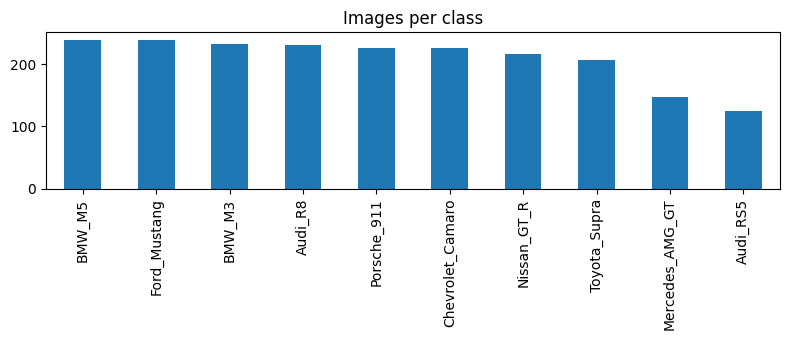

In [3]:
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted([d.name for d in pathlib.Path(DATA_DIR).iterdir() if d.is_dir()])
class_to_idx = {c: i for i, c in enumerate(class_names)}

paths, labels, bad = [], [], []
for c in class_names:
    for f in (pathlib.Path(DATA_DIR) / c).iterdir():
        if f.suffix.lower() not in VALID_EXT: continue
        try:
            with Image.open(f) as im: im.verify()      # skip corrupted files
            paths.append(str(f)); labels.append(class_to_idx[c])
        except Exception:
            bad.append(str(f))
paths, labels = np.array(paths), np.array(labels)
NUM_CLASSES = len(class_names)
print(f"{len(paths)} valid images | {NUM_CLASSES} classes | {len(bad)} corrupted files skipped")

counts = pd.Series(labels).map(dict(enumerate(class_names))).value_counts()
print(counts.describe())
counts.plot(kind="bar", figsize=(max(8, NUM_CLASSES * 0.25), 3.5), title="Images per class", legend=False)
plt.tight_layout(); plt.show()

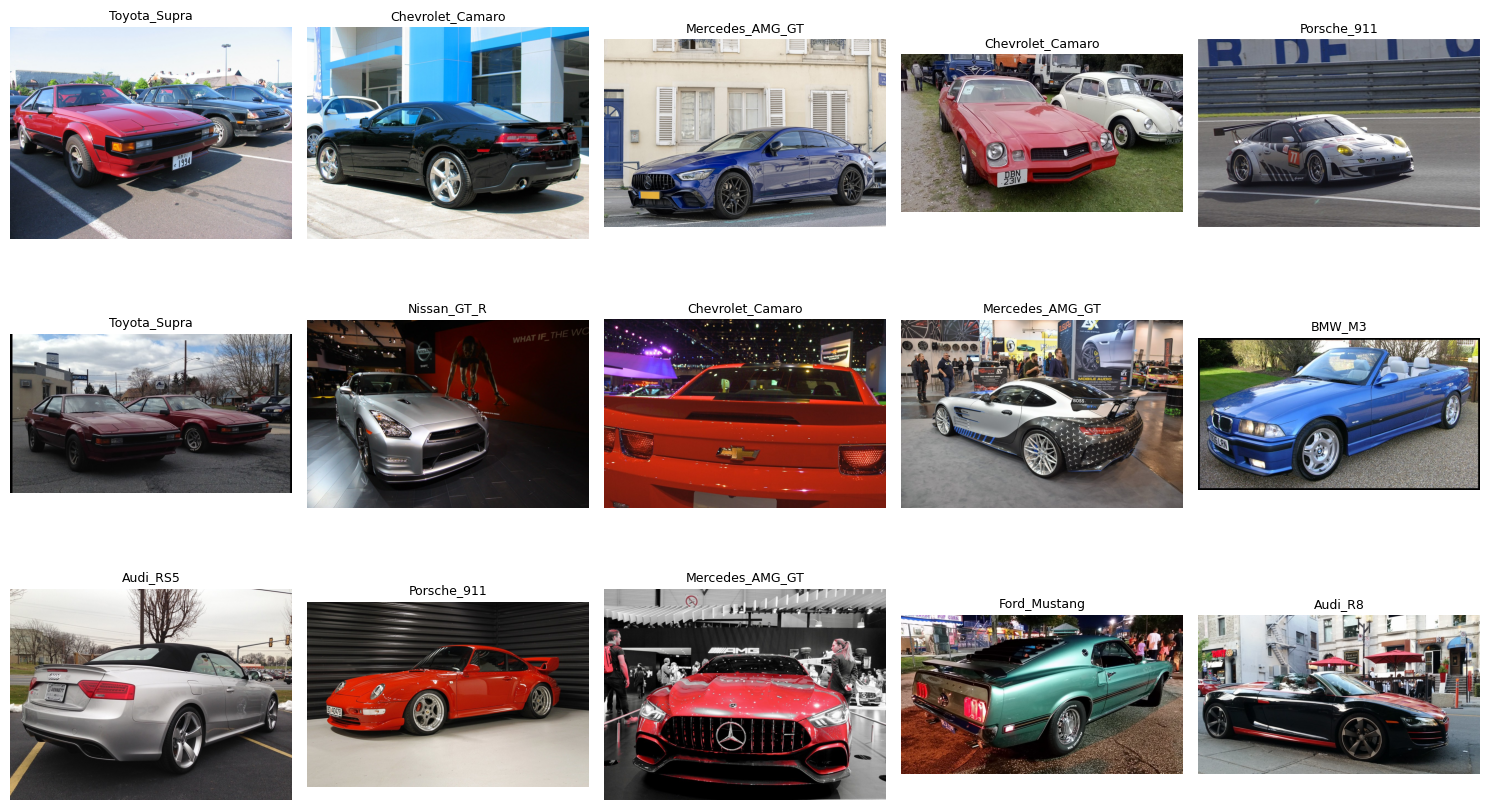

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, i in zip(axes.ravel(), np.random.choice(len(paths), 15, replace=False)):
    ax.imshow(Image.open(paths[i]).convert("RGB")); ax.set_title(class_names[labels[i]], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Data Preprocessing

In [5]:
# Stratified 70 / 15 / 15 split on file paths (every class appears in every split)
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_te, y_val, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(len(p_tr), len(p_val), len(p_te))

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training: ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(load_img, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(p_tr, y_tr, True), make_ds(p_val, y_val), make_ds(p_te, y_te)

1458 313 313


## 6. Model Architecture
- **Augmentation** (training only): random flip, rotation, zoom, contrast.
- **Rescaling** to [-1, 1] (what MobileNetV2 expects).
- **MobileNetV2** convolutional base, pre-trained on ImageNet.
- **GlobalAveragePooling → Dropout → Dense(softmax)** classification head.

In [6]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
    layers.RandomZoom(0.15), layers.RandomContrast(0.15),
], name="augmentation")

base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=min(5, NUM_CLASSES), name="top5")])
compile_model(1e-3)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Training
**Phase 1:** train only the new head. **Phase 2:** unfreeze the top of the base network and fine-tune with a much lower learning rate.

In [7]:
cb = lambda: [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
              keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7)]

print("--- Phase 1: training the head ---")
h1 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb(), verbose=2)

print("--- Phase 2: fine-tuning ---")
base.trainable = True
for layer in base.layers[:-40]:        # keep early (generic) layers frozen
    layer.trainable = False
for layer in base.layers:              # keep BatchNorm layers frozen for stability on a small dataset
    if isinstance(layer, layers.BatchNormalization): layer.trainable = False
compile_model(1e-5)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=25, callbacks=cb(), verbose=2)

--- Phase 1: training the head ---
Epoch 1/20
46/46 - 18s - 385ms/step - accuracy: 0.1550 - loss: 2.5198 - top5: 0.5789 - val_accuracy: 0.2748 - val_loss: 2.0402 - val_top5: 0.7348 - learning_rate: 0.0010
Epoch 2/20
46/46 - 14s - 298ms/step - accuracy: 0.2586 - loss: 2.0719 - top5: 0.7565 - val_accuracy: 0.3482 - val_loss: 1.8566 - val_top5: 0.8466 - learning_rate: 0.0010
Epoch 3/20
46/46 - 6s - 141ms/step - accuracy: 0.3512 - loss: 1.8623 - top5: 0.8409 - val_accuracy: 0.4058 - val_loss: 1.7519 - val_top5: 0.8498 - learning_rate: 0.0010
Epoch 4/20
46/46 - 10s - 224ms/step - accuracy: 0.4060 - loss: 1.7211 - top5: 0.8642 - val_accuracy: 0.3994 - val_loss: 1.7610 - val_top5: 0.8435 - learning_rate: 0.0010
Epoch 5/20
46/46 - 7s - 141ms/step - accuracy: 0.4280 - loss: 1.6519 - top5: 0.8930 - val_accuracy: 0.3930 - val_loss: 1.7067 - val_top5: 0.8786 - learning_rate: 0.0010
Epoch 6/20
46/46 - 6s - 141ms/step - accuracy: 0.4431 - loss: 1.5880 - top5: 0.8930 - val_accuracy: 0.4249 - val_loss

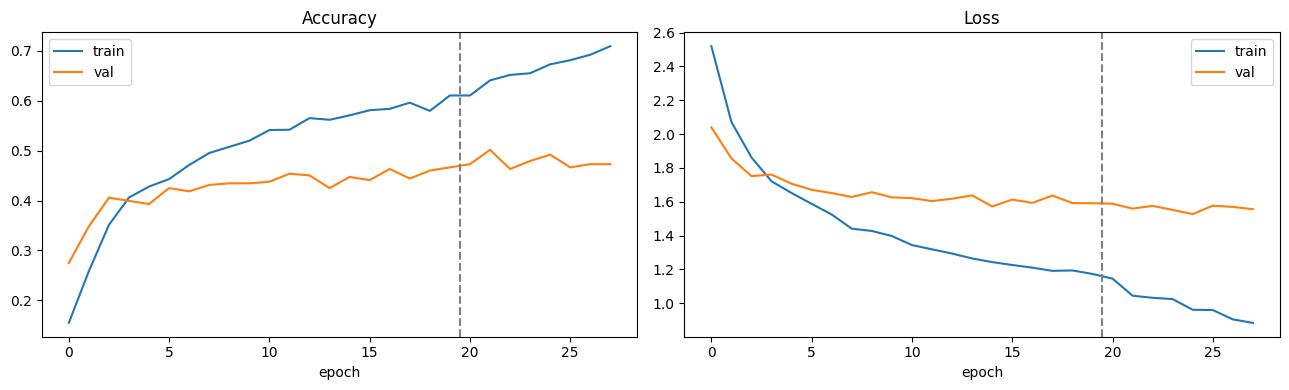

In [8]:
hist = pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["accuracy"], label="train"); ax[0].plot(hist["val_accuracy"], label="val"); ax[0].set_title("Accuracy")
ax[1].plot(hist["loss"], label="train"); ax[1].plot(hist["val_loss"], label="val"); ax[1].set_title("Loss")
for a in ax: a.axvline(len(h1.history["loss"]) - 0.5, ls="--", c="gray"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 8. Evaluation on the Held-Out Test Set

In [9]:
res = model.evaluate(test_ds, verbose=0, return_dict=True)
print({k: round(v, 4) for k, v in res.items()})

probs = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(1)
print("\nTest accuracy: %.4f" % accuracy_score(y_te, y_pred))
print(classification_report(y_te, y_pred, labels=range(NUM_CLASSES), target_names=class_names, zero_division=0))

{'accuracy': 0.4984, 'loss': 1.5673, 'top5': 0.8786}

Test accuracy: 0.4984
                  precision    recall  f1-score   support

         Audi_R8       0.61      0.57      0.59        35
        Audi_RS5       1.00      0.33      0.50        18
          BMW_M3       0.43      0.29      0.34        35
          BMW_M5       0.53      0.78      0.63        36
Chevrolet_Camaro       0.61      0.41      0.49        34
    Ford_Mustang       0.44      0.64      0.52        36
 Mercedes_AMG_GT       0.80      0.36      0.50        22
     Nissan_GT_R       0.37      0.59      0.46        32
     Porsche_911       0.42      0.47      0.44        34
    Toyota_Supra       0.50      0.39      0.44        31

        accuracy                           0.50       313
       macro avg       0.57      0.48      0.49       313
    weighted avg       0.54      0.50      0.49       313



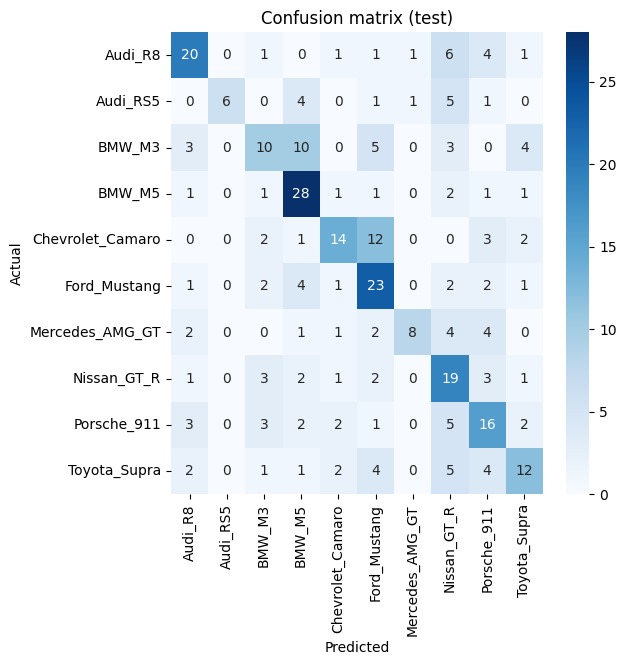

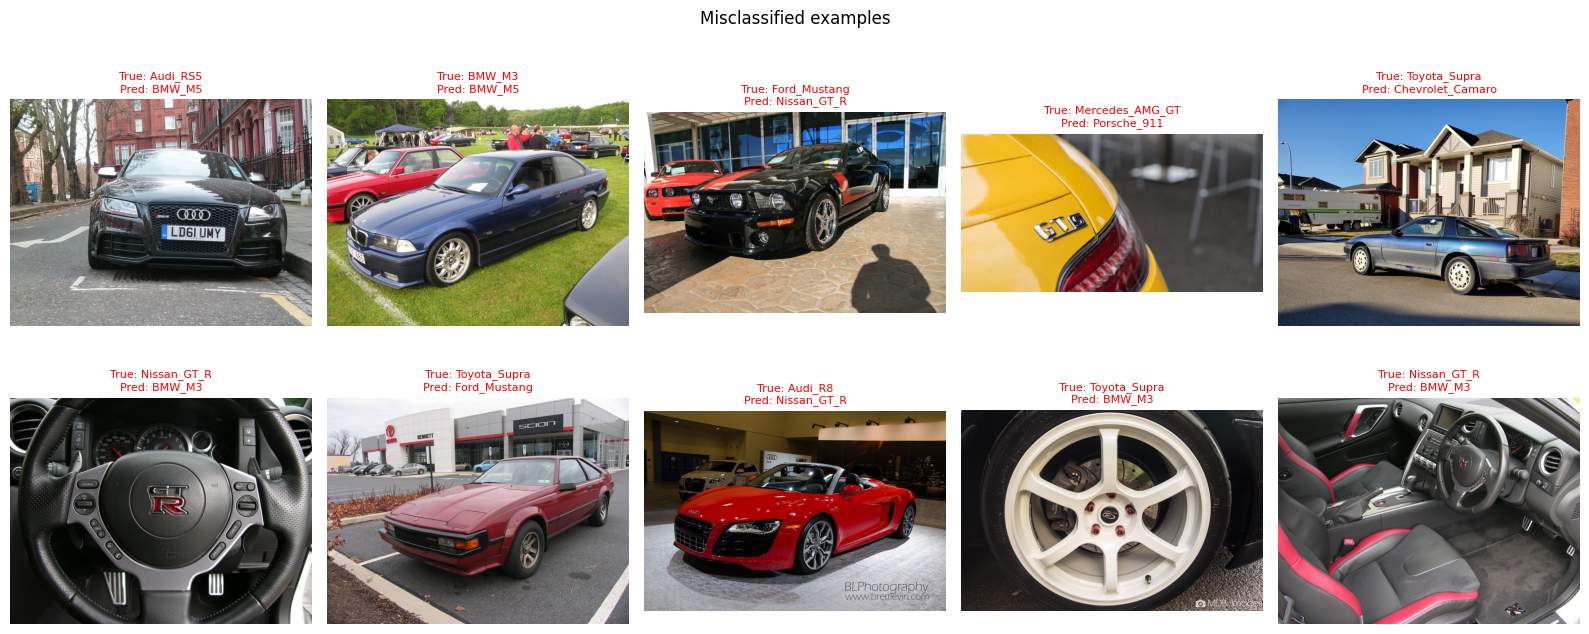

In [10]:
cm = confusion_matrix(y_te, y_pred, labels=range(NUM_CLASSES))
size = min(max(6, NUM_CLASSES * 0.4), 24)
plt.figure(figsize=(size, size))
sns.heatmap(cm, cmap="Blues", annot=NUM_CLASSES <= 15, fmt="d", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test)"); plt.show()

wrong = np.where(y_pred != y_te)[0][:10]
if len(wrong):
    fig, axes = plt.subplots(2, 5, figsize=(16, 7))
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(Image.open(p_te[i]).convert("RGB")); ax.axis("off")
        ax.set_title(f"True: {class_names[y_te[i]]}\nPred: {class_names[y_pred[i]]}", fontsize=8, color="red")
    plt.suptitle("Misclassified examples"); plt.tight_layout(); plt.show()

## 9. Saving the Model (.joblib)

In [11]:
bundle = {
    "model_json": model.to_json(),
    "weights": model.get_weights(),
    "class_names": class_names,
    "img_size": IMG_SIZE,
}
joblib.dump(bundle, "car_cnn_model.joblib")
model.save("car_cnn_model.keras")      # native Keras copy as a backup
print("Saved car_cnn_model.joblib (%.1f MB) and car_cnn_model.keras" % (os.path.getsize("car_cnn_model.joblib") / 1e6))

Saved car_cnn_model.joblib (9.3 MB) and car_cnn_model.keras


## 10. Inference
Load the `.joblib` file and classify any car photo.

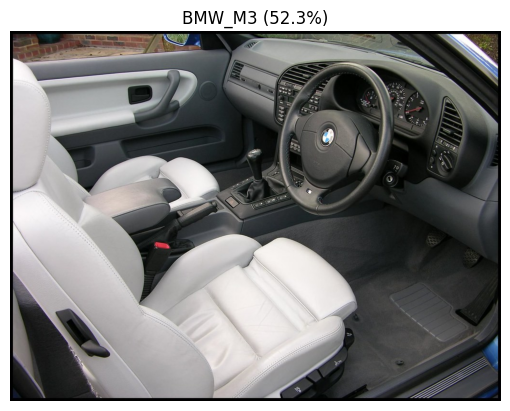

BMW_M3                         52.28%
Nissan_GT_R                    31.74%
Porsche_911                    11.34%


In [12]:
def load_car_model(path="car_cnn_model.joblib"):
    b = joblib.load(path)
    m = keras.models.model_from_json(b["model_json"])
    m.set_weights(b["weights"])
    return m, b

def predict_car(image_path, top_k=3, model_path="car_cnn_model.joblib", show=True):
    m, b = load_car_model(model_path)
    img = Image.open(image_path).convert("RGB")
    arr = np.expand_dims(np.array(img.resize((b["img_size"], b["img_size"])), dtype="float32"), 0)
    p = m.predict(arr, verbose=0)[0]
    top = p.argsort()[::-1][:top_k]
    if show:
        plt.imshow(img); plt.axis("off"); plt.title(f"{b['class_names'][top[0]]} ({p[top[0]]:.1%})"); plt.show()
    return [(b["class_names"][i], float(p[i])) for i in top]

# Try it on a test image (replace with any path to your own car photo)
for name, conf in predict_car(p_te[0]):
    print(f"{name:30s} {conf:.2%}")

## 11. Conclusion
- Transfer learning with MobileNetV2 gives a strong car-model classifier from only ~100 images per class; training a CNN from scratch on this little data would overfit.
- Results are reported on a stratified held-out test set using accuracy, top-5 accuracy and per-class precision/recall.
- Errors mostly occur between visually similar models (e.g. same make, different generation), as the confusion matrix and misclassified examples show.
- **Limitations:** small test set per class (~15 images), possible near-duplicate photos across splits, viewpoint/lighting bias.
- **Future work:** larger backbone (EfficientNet), more data, test-time augmentation, deployment as a web app.